In [1]:
from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(..., description="what to cover")

In [ ]:
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [5]:
class State(TypedDict):
    topic: str
    plan: Plan
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str], operator.add]
    final: str  

In [6]:
llm = ChatGroq(model="openai/gpt-oss-20b")

In [7]:
def orchestrator(state: State) -> dict:

    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(content=("Create a blog plan with 5-7 sections on the following topics.")),
            HumanMessage(content=f"Topic: {state['topic']}")
        ]
    )

    return {"plan": plan}

In [16]:
# an intermediate function before the worker node
# this function runs the worker node for each task
def fanout(state: State) -> dict:
    return [Send("worker", {"task": task, "topic": state["topic"], "plan": state["plan"]})
            for task in state["plan"].tasks]

In [17]:
def worker(payload: dict) -> dict:

    # payload contains what we sent
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(content=(
                f"Blog: {blog_title}\n"
                f"Topic: {topic}\n"
                f"Blog: {task.title}\n"
                f"Brief: {task.brief}\n"
                "Return only the section content in Markdown."
            ))
        ]
    ).content.strip()

    return {"sections": [section_md]}

In [ ]:
import re
from pathlib import Path

# fix the different symbols used by gpt-oss model for showing maths symbols in .md
def fix_math(md: str) -> str:
    md = re.sub(r"\\\[(.+?)\\\]", r"$$\1$$", md, flags=re.DOTALL)  # \[ ... \] -> $$ ... $$
    md = re.sub(r"\\\((.+?)\\\)", r"$\1$", md, flags=re.DOTALL)    # \( ... \) -> $ ... $
    return md


def reducer(state: State) -> dict:
    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()
    final_md = f"# {title}\n\n{body}\n"
    final_md = fix_math(f"# {title}\n\n{body}\n")

    # keep only letters/digits, turn everything else into "_"
    safe = re.sub(r"[^\w]+", "_", title.lower(), flags=re.ASCII).strip("_")
    output_path = Path(f"{safe or 'blog'}.md")
    output_path.write_text(final_md, encoding="utf-8")

    return {"final": final_md}

In [42]:
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer, defer=True)

In [43]:
g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])     # decides how many worker nodes to create
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

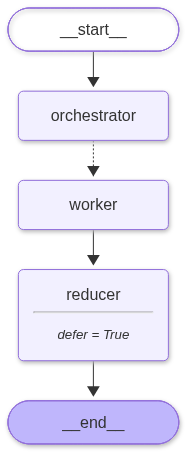

In [44]:
app = g.compile()
app

In [45]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []})

In [46]:
out

{'topic': 'Write a blog on Self Attention',
 'plan': Plan(blog_title='Understanding Self-Attention: From Theory to Practice', tasks=[Task(id=1, title='Introduction to Self-Attention', brief='Explain the basic concept of self-attention and why it is a key component in modern NLP models like Transformers.'), Task(id=2, title='Historical Context and Evolution', brief='Trace the origins of self-attention, from early attention mechanisms to its adoption in the Transformer architecture.'), Task(id=3, title='Mathematical Foundations', brief='Dive into the equations behind self-attention: query, key, value matrices, dot‑product scaling, and the softmax weighting.'), Task(id=4, title='Implementation in Transformers', brief='Show how self‑attention is implemented in practice, including multi‑head attention, positional encodings, and layer normalization.'), Task(id=5, title='Applications and Benefits', brief='Illustrate real‑world use cases—machine translation, language modeling, vision transform